#### Logic for imports
1. **`Pandas`** reads, cleans, and filters the raw datasets.
2. **`NumPy`** optimizes the internal mathematical transformations on those data columns.
3. **`Matplotlib`** renders the final structured data into charts to uncover patterns.
4. **`train_test_split`** splits the dataset into separate training and testing subsets to evaluate model performance.
5. **`KFold`** splits the data into multiple chunks to run cross-validation and ensure the model is stable.
6. **`OneHotEncoder`** converts non-ordered text categories into columns of 0s and 1s for the model to read.
7. **`OrdinalEncoder`** converts ordered text categories into ranked numbers like 0, 1, and 2.
8. **`ColumnTransformer`** applies different preprocessing operations to different columns at the same time.
9. **`Pipeline`** chains data cleaning steps and machine learning models together into a single, automated workflow.
10. **`SimpleImputer`** automatically finds and fills in missing or blank values in the dataset.
11. **`mean_squared_error`** calculates the average squared difference between the model's predictions and actual answers.
12. **`RandomForestRegressor`** trains multiple independent decision trees and averages their predictions to improve accuracy.
13. **`GradientBoostingRegressor`** trains decision trees sequentially, where each new tree corrects the errors of the previous one.


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.metrics import mean_squared_error

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor


#### Loading Datasets
1. **`train = pd.read_csv("house_train.csv")`** loads the historical data used to train the machine learning model.
2. **`test = pd.read_csv("house_test.csv")`** loads the unseen data used to test and evaluate the model's accuracy.

In [1]:
train = pd.read_csv("house_train.csv")
test = pd.read_csv("house_test.csv")

NameError: name 'pd' is not defined

#### Checking Dataset Dimensions
1. **`print("Train shape:", train.shape)`** displays the exact number of rows and columns inside the training dataset to understand its overall size.


In [6]:
print("Train shape:", train.shape)


Train shape: (1460, 81)


#### Checking Dataset Dimensions
1. **`print("Test shape:", test.shape)`** displays the exact number of rows and columns inside the test dataset to verify its structure before running predictions.


In [7]:
print("Test shape:", test.shape)

Test shape: (1459, 80)


#### Previewing the Training Data
1. **`train.head()`** displays the first five rows of the training dataset to inspect the actual values and columns.


In [8]:
train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


#### Inspecting Dataset Information
1. **`train.info()`** prints a detailed summary of the training dataset, including the total number of rows, column data types, and the count of non-missing values.


In [9]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

#### Previewing the Test Data
1. **`test.head()`** displays the first five rows of the test dataset to inspect its structure and values before making predictions.


In [10]:
test.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1461,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,...,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
1,1462,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
2,1463,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal
3,1464,60,RL,78.0,9978,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,6,2010,WD,Normal
4,1465,120,RL,43.0,5005,Pave,NaN,IR1,HLS,AllPub,...,144,0,NaN,NaN,NaN,0,1,2010,WD,Normal


#### Inspecting Test Dataset Information
1. **`test.info()`** prints a detailed summary of the test dataset, including its rows, column data types, and the count of non-missing values to verify it matches the training data format.


In [11]:
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1459 entries, 0 to 1458
Data columns (total 80 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1459 non-null   int64  
 1   MSSubClass     1459 non-null   int64  
 2   MSZoning       1455 non-null   object 
 3   LotFrontage    1232 non-null   float64
 4   LotArea        1459 non-null   int64  
 5   Street         1459 non-null   object 
 6   Alley          107 non-null    object 
 7   LotShape       1459 non-null   object 
 8   LandContour    1459 non-null   object 
 9   Utilities      1457 non-null   object 
 10  LotConfig      1459 non-null   object 
 11  LandSlope      1459 non-null   object 
 12  Neighborhood   1459 non-null   object 
 13  Condition1     1459 non-null   object 
 14  Condition2     1459 non-null   object 
 15  BldgType       1459 non-null   object 
 16  HouseStyle     1459 non-null   object 
 17  OverallQual    1459 non-null   int64  
 18  OverallC

#### Statistical Summary of Training Data
1. **`train.describe()`** calculates statistical metrics—such as mean, median, standard deviation, minimum, and maximum—for all numerical columns in the training dataset.


In [12]:
train.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


#### Separating Features
1. **`X = train.drop("SalePrice", axis=1)`** removes the target variable (`SalePrice`) from the training dataset to isolate the feature columns used for making predictions.


In [13]:
X = train.drop("SalePrice", axis=1)

#### Isolating the Target Variable
1. **`y = train["SalePrice"]`** extracts the target variable column (`SalePrice`) into a separate series to represent the values the model needs to learn to predict.


In [14]:
y = train["SalePrice"]

#### Checking Feature Dimensions
1. **`print("X shape:", X.shape)`** displays the exact number of rows and columns in the features dataset to confirm the target variable was successfully removed.


In [15]:
print("X shape:", X.shape)

X shape: (1460, 80)


#### Checking Target Dimensions
1. **`print("y shape:", y.shape)`** displays the total number of labels in the target variable to confirm it perfectly matches the row count of your features.


In [16]:
print("y shape:", y.shape)

y shape: (1460,)


#### Visualizing House Price Distribution
1. **`plt.figure(figsize=(8, 5))`** initializes a canvas window measuring 8 inches wide and 5 inches high to ensure the chart is easily readable.
2. **`plt.hist(y, bins=50)`** builds a histogram plot by partitioning the `SalePrice` values into 50 equal bins to show how house prices are grouped.
3. **`plt.xlabel("SalePrice")`** attaches a horizontal axis label to denote that the x-axis measures individual home pricing.
4. **`plt.ylabel("Number of Houses")`** attaches a vertical axis label to denote that the y-axis measures the frequency of homes in each bin.
5. **`plt.title("Distribution of House Prices")`** adds an overarching descriptive header text to the top of the generated visualization window.
6. **`plt.show()`** forces the notebook interface to finalize and display the complete plotted chart cleanly on the screen.


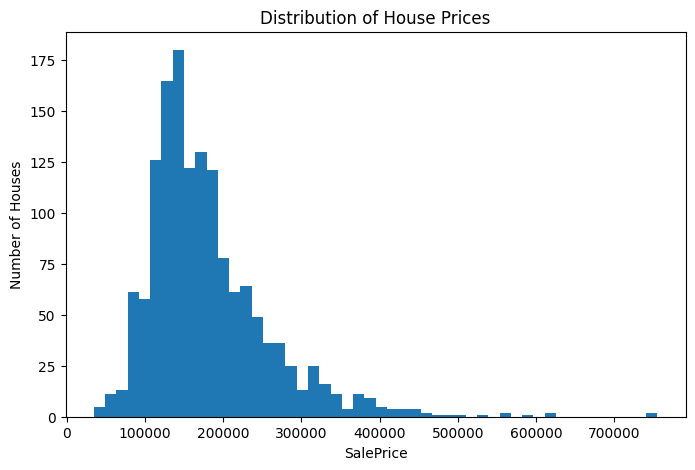

In [17]:
plt.figure(figsize=(8, 5))

plt.hist(y, bins=50)

plt.xlabel("SalePrice")
plt.ylabel("Number of Houses")
plt.title("Distribution of House Prices")

plt.show()

#### Log-Transforming the Target Variable
1. **`y_log = np.log1p(y)`** applies a natural log transformation plus one to the `SalePrice` values to handle right-skewed data and make the distribution more normal for modeling.


In [18]:
y_log = np.log1p(y)

#### Visualizing the Log-Transformed Target Variable
1. **`plt.figure(figsize=(8, 5))`** sets up a canvas window measuring 8 inches wide and 5 inches high to ensure the new chart is clearly visible.
2. **`plt.hist(y_log, bins=50)`** creates a histogram of the log-transformed prices using 50 bins to examine the shape of the modified distribution.
3. **`plt.xlabel("log(SalePrice)")`** adds a horizontal axis label to show that the scale now represents the log-transformed house values.
4. **`plt.ylabel("Number of Houses")`** adds a vertical axis label to show the frequency of homes within each log-price bucket.
5. **`plt.title("Log Transformed SalePrice")`** places a descriptive title at the top of the chart to clearly label the plot.
6. **`plt.show()`** renders the final visualization cleanly in the notebook, allowing you to verify that the target variable now follows a more normal, symmetrical distribution.


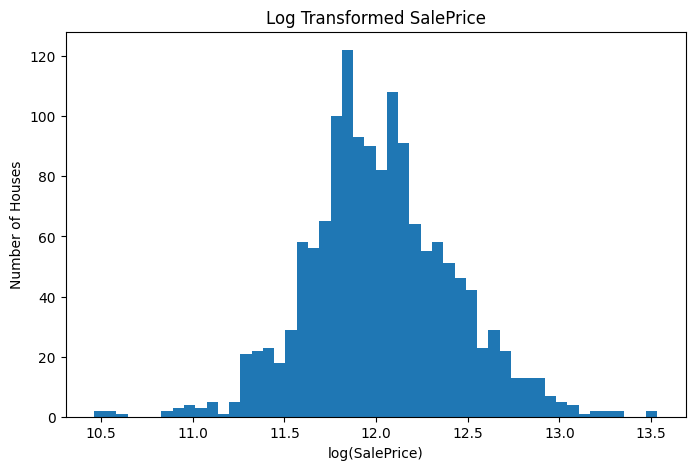

In [19]:
plt.figure(figsize=(8, 5))

plt.hist(y_log, bins=50)

plt.xlabel("log(SalePrice)")
plt.ylabel("Number of Houses")
plt.title("Log Transformed SalePrice")

plt.show()

#### Reasoning About Missing Values Before Doing Anything Else
1. In the Ames housing data, most `NaN`s are not really "missing" — for features like `Alley`, `BsmtQual`, `GarageType`, or `PoolQC`, `NaN` is how the source data says "this house doesn't have that feature" (no alley, no basement, no garage, no pool).
2. Filling those with a median or a guessed category would invent information that isn't there; they need their own explicit "None" (or `0` for the numeric side-columns tied to the same feature, e.g. `GarageArea`).
3. A much smaller set of columns are truly missing — a value exists in reality but wasn't recorded (e.g. `LotFrontage`, `Electrical`, `MSZoning`). Those are the only ones that should get a statistical imputer (median/most-frequent).


In [2]:
none_categorical_cols = [
    "Alley", "MasVnrType", "BsmtQual", "BsmtCond", "BsmtExposure",
    "BsmtFinType1", "BsmtFinType2", "FireplaceQu", "GarageType",
    "GarageFinish", "GarageQual", "GarageCond", "PoolQC", "Fence", "MiscFeature"
]

zero_numeric_cols = [
    "GarageYrBlt", "GarageArea", "GarageCars",
    "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF",
    "BsmtFullBath", "BsmtHalfBath", "MasVnrArea"
]

def fill_structural_missing(df):
    """Fill NaNs that encode \"no such feature\", leaving genuine missing values untouched
    so the imputers further down the pipeline handle those instead."""
    df = df.copy()
    df[none_categorical_cols] = df[none_categorical_cols].fillna("None")
    df[zero_numeric_cols] = df[zero_numeric_cols].fillna(0)
    return df

X = fill_structural_missing(X)
test = fill_structural_missing(test)


NameError: name 'X' is not defined

#### Fixing MSSubClass's Type Before Encoding
1. `MSSubClass` stores a building-class *code* (20, 60, 120, ...) as an integer, but the numbers are labels, not a quantity — a 120 is not "more" of anything than a 20.
2. Left as `int64`, it would land in `numerical_cols` and get median-imputed and fed to the model as a magnitude, which would invent a false ordering between building classes.
3. Casting it to a string moves it into the categorical columns, where it gets encoded like the category it actually is.


In [3]:
X["MSSubClass"] = X["MSSubClass"].astype(str)
test["MSSubClass"] = test["MSSubClass"].astype(str)


NameError: name 'X' is not defined

#### Splitting Data into Training and Validation Sets
1. **`X_train, X_valid, y_train, y_valid = train_test_split(...)`** unpacks the randomized data subsets into separate training and validation sets for both features and targets.
2. **`X`** passes the complete matrix of independent input features into the splitting function.
3. **`y_log`** passes the log-transformed target labels into the splitting function to ensure the correct output format.
4. **`test_size=0.2`** allocates 20% of the entire dataset to the validation sets, leaving the remaining 80% for training.
5. **`random_state=42`** sets a static random seed to guarantee that the exact same rows are chosen every time the notebook runs.


In [4]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y_log,
    test_size=0.2,
    random_state=42
)


NameError: name 'train_test_split' is not defined

#### Verifying Train-Test Split Dimensions
1. **`print("Training data:", X_train.shape)`** outputs the exact row and column dimensions of the training feature set to ensure it holds 80% of the data.
2. **`print("Validation data:", X_valid.shape)`** outputs the exact row and column dimensions of the validation feature set to ensure it holds the remaining 20% of the data.


In [21]:
print("Training data:", X_train.shape)
print("Validation data:", X_valid.shape)

Training data: (1168, 80)
Validation data: (292, 80)


#### Matching Encoding Technique to Variable Type
1. Some categorical columns are genuinely *ranked* — a quality of `Ex` is better than `TA`, which is better than `Fa`. Those get **ordinal encoding** with an explicit worst-to-best scale, so the model can use the ordering directly.
2. Everything else (neighborhood, roof style, sale type, ...) has no inherent order, so those get **one-hot encoding** to avoid inventing a ranking that isn't there.
3. `ordinal_specs` lists each ranked column together with its category order (including `"None"` where "no such feature" is itself the lowest rung, e.g. no basement is worse than a poor basement).


In [ ]:
ordinal_specs = {
    "LotShape":     ["IR3", "IR2", "IR1", "Reg"],
    "LandSlope":    ["Sev", "Mod", "Gtl"],
    "Utilities":    ["NoSeWa", "AllPub"],
    "ExterQual":    ["Po", "Fa", "TA", "Gd", "Ex"],
    "ExterCond":    ["Po", "Fa", "TA", "Gd", "Ex"],
    "BsmtQual":     ["None", "Po", "Fa", "TA", "Gd", "Ex"],
    "BsmtCond":     ["None", "Po", "Fa", "TA", "Gd", "Ex"],
    "BsmtExposure": ["None", "No", "Mn", "Av", "Gd"],
    "BsmtFinType1": ["None", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    "BsmtFinType2": ["None", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    "HeatingQC":    ["Po", "Fa", "TA", "Gd", "Ex"],
    "KitchenQual":  ["Po", "Fa", "TA", "Gd", "Ex"],
    "Functional":   ["Sal", "Sev", "Maj2", "Maj1", "Mod", "Min2", "Min1", "Typ"],
    "FireplaceQu":  ["None", "Po", "Fa", "TA", "Gd", "Ex"],
    "GarageFinish": ["None", "Unf", "RFn", "Fin"],
    "GarageQual":   ["None", "Po", "Fa", "TA", "Gd", "Ex"],
    "GarageCond":   ["None", "Po", "Fa", "TA", "Gd", "Ex"],
    "PavedDrive":   ["N", "P", "Y"],
    "PoolQC":       ["None", "Fa", "TA", "Gd", "Ex"],
}

ordinal_cols = list(ordinal_specs.keys())
ordinal_categories = list(ordinal_specs.values())

categorical_cols = X_train.select_dtypes(include=["object"]).columns.tolist()
nominal_cols = [c for c in categorical_cols if c not in ordinal_cols]

numerical_cols = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Ordinal columns:", len(ordinal_cols))
print("One-hot columns:", len(nominal_cols))
print("Numerical columns:", len(numerical_cols))


#### Identifying Feature Types by Data Type
1. **`categorical_cols = X_train.select_dtypes(include=["object"]).columns.tolist()`** filters the training columns to find text-based features and saves them as a list of strings.
2. **`numerical_cols = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()`** filters the training columns to find integer and decimal features and saves them as a list of strings.
3. **`print("Categorical columns:", len(categorical_cols))`** counts and displays the total number of text-based features present in the dataset.
4. **`print("Numerical columns:", len(numerical_cols))`** counts and displays the total number of numeric features present in the dataset.


In [22]:
categorical_cols = X_train.select_dtypes(include=["object"]).columns.tolist()

numerical_cols = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Categorical columns:", len(categorical_cols))
print("Numerical columns:", len(numerical_cols))


Categorical columns: 43
Numerical columns: 37


#### Listing Categorical Features
1. **`print(categorical_cols)`** prints the exact name of every text-based categorical column to inspect which text features will need encoding.


In [23]:
print(categorical_cols)

['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition']


#### Building the Preprocessing Pipeline
1. **`preprocessor = ColumnTransformer(transformers=[...])`** initializes a central manager that applies specific data cleaning rules to different groups of columns simultaneously.
2. **`("num", SimpleImputer(strategy="median"), numerical_cols)`** isolates all numeric features and fills any blank cells using the middle value of that specific column.
3. **`("categorical_features", Pipeline([...]), categorical_cols)`** creates a multi-step sub-workflow specifically for transforming text-based features.
4. **`("imputer", SimpleImputer(strategy="most_frequent"))`** patches missing text data by filling blanks with the most common word in that column.
5. **`("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))`** converts text categories into numbers, safely ignoring new unexpected categories and outputting a standard flat matrix instead of a sparse one.


In [24]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            SimpleImputer(strategy="median"),
            numerical_cols
        ),
        (
            "categorical_features",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                (
                    "encoder",
                    OneHotEncoder(
                        handle_unknown="ignore",
                        sparse_output=False
                    )
                )
            ]),
            categorical_cols
        )
    ]
)

#### Fitting and Transforming the Features
1. **`X_train_encoded = preprocessor.fit_transform(X_train)`** learns the statistical patterns (like medians and categories) from the training features and immediately transforms them into a cleaned, numerical matrix.
2. **`X_valid_encoded = preprocessor.transform(X_valid)`** applies those exact same learned rules to the validation features to ensure consistency and prevent data leakage.


In [34]:
X_train_encoded = preprocessor.fit_transform(X_train)

X_valid_encoded = preprocessor.transform(X_valid)


#### Checking Encoded Feature Dimensions
1. **`print("Encoded training shape:", X_train_encoded.shape)`** displays the exact number of rows and columns in the processed training matrix to see how many new columns were generated by one-hot encoding.
2. **`print("Encoded validation shape:", X_valid_encoded.shape)`** displays the dimensions of the processed validation matrix to verify that its column count perfectly matches the training set.


In [35]:
print("Encoded training shape:", X_train_encoded.shape)
print("Encoded validation shape:", X_valid_encoded.shape)

Encoded training shape: (1168, 286)
Encoded validation shape: (292, 286)


#### Initializing the Random Forest Regressor
1. **`model = RandomForestRegressor(...)`** instantiates a tree-based ensemble machine learning model designed for forecasting continuous target values.
2. **`n_estimators=300`** instructs the algorithm to build an ensemble ensemble of 300 independent decision trees to vote on the final prediction.
3. **`max_depth=15`** restricts the growth of each tree to a maximum depth of 15 levels to prevent complex over-fitting on noise.
4. **`min_samples_split=5`** requires a decision node to contain at least 5 individual data samples before it can split into smaller branches.
5. **`min_samples_leaf=2`** forces each terminal leaf node at the bottom of a tree to hold a minimum of 2 data points.
6. **`max_features="sqrt"`** limits each tree split to randomly evaluate only the square root of the total number of available features.
7. **`random_state=42`** locks down the internal random selection patterns to guarantee completely identical predictions across notebook runs.
8. **`n_jobs=-1`** directs the algorithm to use all available computer processor cores in parallel to accelerate model training.


In [36]:
model = RandomForestRegressor(
    n_estimators=300,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

#### Training the Model
1. **`model.fit(X_train_encoded, y_train)`** trains the Random Forest algorithm by matching the cleaned training features with their corresponding target prices so the model can learn the underlying patterns.


In [37]:
model.fit(X_train_encoded, y_train)


,n_estimators,300
,criterion,'squared_error'
,max_depth,15
,min_samples_split,5
,min_samples_leaf,2
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


#### Generating Model Predictions
1. **`train_predictions = model.predict(X_train_encoded)`** uses the trained Random Forest model to calculate predicted house prices for the training dataset.
2. **`valid_predictions = model.predict(X_valid_encoded)`** uses the trained Random Forest model to calculate predicted house prices for the validation dataset to assess performance on unseen data.


In [38]:
train_predictions = model.predict(X_train_encoded)

valid_predictions = model.predict(X_valid_encoded)


#### Evaluating Model Performance using RMSE
1. **`train_rmse = np.sqrt(mean_squared_error(y_train, train_predictions))`** calculates the Root Mean Squared Error for the training data to measure how far off the model's training guesses are on average.
2. **`valid_rmse = np.sqrt(mean_squared_error(y_valid, valid_predictions))`** calculates the Root Mean Squared Error for the validation data to measure the model's true error on unseen data.
3. **`print("Training RMSE:", train_rmse)`** outputs the final training error score directly in the notebook console interface.
4. **`print("Validation RMSE:", valid_rmse)`** outputs the final validation error score directly in the notebook console interface to check for overfitting.


In [39]:
train_rmse = np.sqrt(
    mean_squared_error(y_train, train_predictions)
)

valid_rmse = np.sqrt(
    mean_squared_error(y_valid, valid_predictions)
)

print("Training RMSE:", train_rmse)
print("Validation RMSE:", valid_rmse)

Training RMSE: 0.09097387141502557
Validation RMSE: 0.16469212208450854


#### Initializing the Gradient Boosting Regressor
1. **`gb_model = GradientBoostingRegressor(...)`** instantiates an ensemble model that builds decision trees sequentially to minimize prediction errors.
2. **`n_estimators=1000`** sets the total number of sequential decision trees to be built during training.
3. **`learning_rate=0.03`** controls the step size taken to minimize the loss function, scaling down the contribution of each new tree.
4. **`max_depth=3`** limits the maximum depth of each individual tree to capture weak, simple patterns and prevent overfitting.
5. **`min_samples_leaf=5`** requires a minimum of 5 data points at the terminal leaf nodes to smooth out local predictions.
6. **`min_samples_split=10`** sets the minimum number of data samples required to split an internal decision node.
7. **`subsample=0.8`** trains each individual tree on a random 80% subset of the data to introduce randomness and prevent variance.
8. **`random_state=42`** locks the pseudo-random sampling parameters to guarantee reproducible results across runs.


In [40]:
gb_model = GradientBoostingRegressor(
    n_estimators=1000,
    learning_rate=0.03,
    max_depth=3,
    min_samples_leaf=5,
    min_samples_split=10,
    subsample=0.8,
    random_state=42
)

#### Gradient Boosting Hyperparameters
1. **`max_depth=3`** limits the maximum depth of each individual tree to capture weak, simple patterns and prevent overfitting.
2. **`min_samples_leaf=5`** requires a minimum of 5 data points at the terminal leaf nodes to smooth out local predictions.
3. **`subsample=0.8`** trains each individual tree on a random 80% subset of the data to introduce randomness and prevent variance.
4. **`learning_rate=0.03`** controls the step size taken to minimize the loss function, scaling down the contribution of each new tree.


In [41]:
max_depth=3
min_samples_leaf=5
subsample=0.8
learning_rate=0.03

#### Training the Gradient Boosting Model
1. **`gb_model.fit(X_train_encoded, y_train)`** trains the Gradient Boosting algorithm by sequentially constructing decision trees to correct the residual errors made on the training features and targets.


In [42]:
gb_model.fit(X_train_encoded, y_train)

,loss,'squared_error'
,learning_rate,0.03
,n_estimators,1000
,subsample,0.8
,criterion,'friedman_mse'
,min_samples_split,10
,min_samples_leaf,5
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


#### Generating Gradient Boosting Predictions
1. **`gb_train_predictions = gb_model.predict(X_train_encoded)`** uses the trained Gradient Boosting model to calculate predicted house prices for the training dataset.
2. **`gb_valid_predictions = gb_model.predict(X_valid_encoded)`** uses the trained Gradient Boosting model to calculate predicted house prices for the validation dataset to assess its performance on unseen data.


In [43]:
gb_train_predictions = gb_model.predict(X_train_encoded)

gb_valid_predictions = gb_model.predict(X_valid_encoded)


#### Evaluating Gradient Boosting Performance using RMSE
1. **`gb_train_rmse = np.sqrt(mean_squared_error(y_train, gb_train_predictions))`** calculates the Root Mean Squared Error for the training data to measure the average prediction error of the Gradient Boosting model on the training set.
2. **`gb_valid_rmse = np.sqrt(mean_squared_error(y_valid, gb_valid_predictions))`** calculates the Root Mean Squared Error for the validation data to measure the model's prediction accuracy on unseen validation data.
3. **`print("Gradient Boosting Training RMSE:", gb_train_rmse)`** outputs the final training error score directly to the console display.
4. **`print("Gradient Boosting Validation RMSE:", gb_valid_rmse)`** outputs the final validation error score directly to the console display to evaluate performance.


In [44]:
gb_train_rmse = np.sqrt(
    mean_squared_error(y_train, gb_train_predictions)
)

gb_valid_rmse = np.sqrt(
    mean_squared_error(y_valid, gb_valid_predictions)
)

print("Gradient Boosting Training RMSE:", gb_train_rmse)
print("Gradient Boosting Validation RMSE:", gb_valid_rmse)


Gradient Boosting Training RMSE: 0.049429504695353205
Gradient Boosting Validation RMSE: 0.13426512951114647


#### Comparing Model Performance Results
1. **`print("Random Forest")`** outputs a clear structural header label indicating that the following metrics belong to the Random Forest model.
2. **`print("Training RMSE:", train_rmse)`** prints the average prediction error margin achieved by the Random Forest model on the training subset.
3. **`print("Validation RMSE:", valid_rmse)`** prints the average prediction error margin achieved by the Random Forest model on the unseen validation dataset.
4. **`print("\nGradient Boosting")`** inserts a clean line break followed by a structural header label for the Gradient Boosting model metrics.
5. **`print("Training RMSE:", gb_train_rmse)`** prints the average prediction error margin achieved by the Gradient Boosting model on the training subset.
6. **`print("Validation RMSE:", gb_valid_rmse)`** prints the average prediction error margin achieved by the Gradient Boosting model on the unseen validation dataset.


In [45]:
print("Random Forest")
print("Training RMSE:", train_rmse)
print("Validation RMSE:", valid_rmse)

print("\nGradient Boosting")
print("Training RMSE:", gb_train_rmse)
print("Validation RMSE:", gb_valid_rmse)


Random Forest
Training RMSE: 0.09097387141502557
Validation RMSE: 0.16469212208450854

Gradient Boosting
Training RMSE: 0.049429504695353205
Validation RMSE: 0.13426512951114647


#### Inverting the Log Transformation on Predictions
1. **`actual_predictions = np.expm1(gb_valid_predictions)`** applies an exponential transformation minus one ($e^x - 1$) to convert the log-scaled validation predictions back into real, original dollar amounts.


In [46]:
actual_predictions = np.expm1(gb_valid_predictions)

#### Inverting the Log Transformation on Actual Labels
1. **`actual_prices = np.expm1(y_valid)`** applies an exponential transformation minus one ($e^x - 1$) to convert the log-scaled actual validation target values back into original, real-world dollar amounts.


In [47]:
actual_prices = np.expm1(y_valid)

#### Creating a Predictions Comparison DataFrame
1. **`comparison = pd.DataFrame({...})`** constructs a new tabular DataFrame to pair the true target values with the model's generated predictions side by side.
2. **`"Actual Price": actual_prices`** maps the real, untransformed market prices to a structured column named "Actual Price".
3. **`"Predicted Price": actual_predictions`** maps the converted, untransformed predicted prices to a matching column named "Predicted Price".
4. **`comparison.head(10)`** slices and outputs the top 10 rows of the comparison table to easily inspect how close the predictions are to the true values.


In [48]:
comparison = pd.DataFrame({
    "Actual Price": actual_prices,
    "Predicted Price": actual_predictions
})

comparison.head(10)


,Actual Price,Predicted Price
892,154500.0,140926.701611
1105,325000.0,342791.779701
413,115000.0,110550.066051
522,159000.0,153003.618368
1036,315500.0,322780.313348
614,75500.0,75813.641712
218,311500.0,242219.568119
1160,146000.0,141270.163723
649,84500.0,75379.593849
887,135500.0,140186.275363
